# Extra exercises for notebook 1: suggested solution

This is the suggested solution for `01_python_basics_extra.ipynb`. The task texts are the same as in the exercise notebook. In the code cells, `___` has been replaced with a solution, and below each written task there is a suggested answer. There are often more correct solutions than the one shown.

Two cells fail on purpose (tasks 1.2 and 4.5). So run the cells one at a time instead of using Run all.

---
## Block 1: Types, errors and printing (for exercise 1)

In [1]:
# Setup for block 1: run this cell first
import numpy as np

price = 45

### Task 1.1: Which type?

Python distinguishes between types of values: integers (`int`), decimal numbers (`float`), text (`str`), true or false (`bool`) and lists (`list`). With `type()` you can always ask which type a value has.

First write your prediction for each of the five values in the cell below. Then run the cell.

*Your prediction:*

In [2]:
print(type(45))
print(type(45.0))
print(type("45"))
print(type(True))
print(type([35, 45]))

<class 'int'>
<class 'float'>
<class 'str'>
<class 'bool'>
<class 'list'>


### Task 1.2: TypeError

The cell below fails on purpose. Run it and read the error message from the bottom up. The bottom line tells you that Python cannot add text (`str`) and a number (`int`) with `+`.

In [3]:
# ⚠️ This cell fails on purpose
print("The price is " + price + " DKK.")

TypeError: can only concatenate str (not "int") to str

Fix the error in two ways in the cells below: first with an f-string, then by turning the number into text with `str(price)`.

In [4]:
# Way 1: with an f-string (write the whole print line)
print(f"The price is {price} DKK.")

The price is 45 DKK.


In [5]:
# Way 2: with str()
print("The price is " + str(price) + " DKK.")

The price is 45 DKK.


In [6]:
#@title Expected output (click to show)
print("Both cells should print:")
print("The price is 45 DKK.")

Both cells should print:
The price is 45 DKK.


### Task 1.3: Numbers stored as text

Data from files and forms sometimes comes in as text, even though it looks like numbers. Run the cell and see what happens.

In [7]:
quantity = "3"
print(quantity * 2)

33


Python repeats the text instead of calculating. Turn `quantity` into an integer with `int()`, and calculate the price of 3 softice at 45 DKK. Store the result in `amount`.

In [8]:
quantity_int = int(quantity)
amount = quantity_int * price
print(f"3 softice cost {amount} DKK.")

3 softice cost 135 DKK.


In [9]:
#@title Check your answer (run the cell)
print("Correct" if amount == 135 else "Not yet: is quantity turned into a number before you multiply?")

Correct


### Task 1.4: Nicely formatted numbers in the output

Inside the curly brackets in an f-string, you can control how a number is shown. You put a colon and a format code after the name, for example `{revenue:.2f}`.

| Format code | Meaning | 12345.678 becomes |
| --- | --- | --- |
| `:.2f` | 2 decimals | 12345.68 |
| `:.0f` | no decimals | 12346 |
| `:,.0f` | thousands separator, no decimals | 12,346 |

Note that Python uses English number format, with a period as the decimal mark and a comma as the thousands separator. In Danish, this is written 12.345,68 kr. The format code only changes how the number is shown, not the number itself.

Print the day's revenue three times, once with each format code, in the sentence `Revenue: ... DKK.`

In [10]:
revenue = 12345.678

In [11]:
# Write three print lines, one for each format code
print(f"Revenue: {revenue:.2f} DKK.")
print(f"Revenue: {revenue:.0f} DKK.")
print(f"Revenue: {revenue:,.0f} DKK.")

Revenue: 12345.68 DKK.
Revenue: 12346 DKK.
Revenue: 12,346 DKK.


In [12]:
#@title Expected output (click to show)
print("Revenue: 12345.68 DKK.")
print("Revenue: 12346 DKK.")
print("Revenue: 12,346 DKK.")

Revenue: 12345.68 DKK.
Revenue: 12346 DKK.
Revenue: 12,346 DKK.


### Task 1.5: The order in which cells are run

A notebook remembers values in the order in which the cells have been **run**, not the order in which they appear. Below are three cells, A, B and C.

1. Predict: What does cell C print if you run A, then B, then B again, and finally C? Try it afterwards.
2. Predict: What does C print if you run A, B and C once each from the top? Try it afterwards.

In [13]:
# Cell A
price = 45

In [14]:
# Cell B
price = price + 5

In [15]:
# Cell C
print(f"The price is now {price} DKK.")

The price is now 50 DKK.


**Answer in words:** What did C print in the two cases, and why is there a difference?

**Suggested solution:** With the order A, B, B, C, cell C prints 55 DKK, because B has been run twice and has added 5 DKK twice. If you run A, B and C once each, C prints 50 DKK. So the notebook remembers what has happened, not what is written. If a notebook behaves strangely, it is a good idea to choose Runtime > Restart session and run the cells again from the top.

### Task 1.6: Without a pattern

Now the task is only given as a comment in the cell. Find the patterns you need yourself, in the earlier tasks of the block or in notebook 1.

In [16]:
# A customer buys 3 softice at 45 DKK and 2 milkshakes at 55 DKK and gets a 10 percent discount.
# Calculate the amount after the discount, store it in the variable amount_discounted, and print it with 2 decimals.
amount_discounted = (3 * 45 + 2 * 55) * 0.9
print(f"Amount after discount: {amount_discounted:.2f} DKK.")

Amount after discount: 220.50 DKK.


In [17]:
#@title Check your answer (run the cell)
print("Correct" if np.isclose(amount_discounted, 220.5) else "Not yet: remember that the discount applies to the whole amount")

Correct


---
## Block 2: Tables, loops and conditions (for exercise 2)

In [18]:
# Setup for block 2: run this cell first
import numpy as np

menu_names = ["Waffle 1 scoop", "Waffle 2 scoops", "Waffle 3 scoops", "Softice", "Milkshake", "Slushice"]
menu = np.array([38, 50, 62, 45, 55, 35])     # the prices as a numpy array
menu_list = [38, 50, 62, 45, 55, 35]          # the same prices as an ordinary list
shops = ["Aalborg C", "Blokhus", "Løkken", "Skagen"]

### Task 2.1: From text to table

The manager has sent the ice cream sales for the first four summer weeks as text:

- Aalborg C sold 210, 230, 250 and 240 ice creams in weeks 1 to 4.
- Blokhus sold 120, 145, 160 and 150.
- Løkken sold 95, 110, 125 and 115.
- Skagen sold 80, 100, 105 and 95.

Create a 2D array named `sales`, where each **row** is a shop (in the order above) and each **column** is a week.

In [19]:
sales = np.array([
    [210, 230, 250, 240],   # Aalborg C
    [120, 145, 160, 150],   # Blokhus
    [ 95, 110, 125, 115],   # Løkken
    [ 80, 100, 105,  95],   # Skagen
])
print(sales)
print(sales.shape)

[[210 230 250 240]
 [120 145 160 150]
 [ 95 110 125 115]
 [ 80 100 105  95]]
(4, 4)


In [20]:
#@title Check your answer (run the cell)
print("Correct" if sales.shape == (4, 4) and sales[2, 1] == 110 else "Not yet: check that the rows are shops and the columns are weeks")

Correct


### Task 2.2: Rows and columns

A row is one shop, and a column is one week.

1. Calculate the total sales in Blokhus over the four weeks (one row and `.sum()`).
2. Calculate the total sales in week 4 for all shops (one column and `.sum()`).
3. `.sum(axis=1)` adds along each row and gives one total per shop. `.sum(axis=0)` adds down each column and gives one total per week. Print both.

In [21]:
# 1. Blokhus in total
blokhus_total = sales[1].sum()

# 2. Week 4 in total
week4_total = sales[:, 3].sum()

print(blokhus_total, week4_total)

# 3. Totals per shop and per week
print(sales.sum(axis=1))
print(sales.sum(axis=0))

575 600
[930 575 445 380]
[505 585 640 600]


In [22]:
#@title Expected output (click to show)
print("575 600")
print("[930 575 445 380]")
print("[505 585 640 600]")

575 600
[930 575 445 380]
[505 585 640 600]


### Task 2.3: A loop with a condition

The loop below should print the campaign price with a 20 percent discount for each item on the menu. Fill in the blank.

In [23]:
for p in menu:
    campaign_price = p * 0.8
    print(f"Campaign price: {campaign_price:.2f} DKK.")

Campaign price: 30.40 DKK.
Campaign price: 40.00 DKK.
Campaign price: 49.60 DKK.
Campaign price: 36.00 DKK.
Campaign price: 44.00 DKK.
Campaign price: 28.00 DKK.


Now the loop should write `expensive` for prices above 50 DKK and `cheap` for all others. Fill in the condition after `if`.

In [24]:
for p in menu:
    if p > 50:
        print(f"{p} DKK: expensive")
    else:
        print(f"{p} DKK: cheap")

38 DKK: cheap
50 DKK: cheap
62 DKK: expensive
45 DKK: cheap
55 DKK: expensive
35 DKK: cheap


In [25]:
#@title Expected output (click to show)
print("38 DKK: cheap")
print("50 DKK: cheap")
print("62 DKK: expensive")
print("45 DKK: cheap")
print("55 DKK: expensive")
print("35 DKK: cheap")

38 DKK: cheap
50 DKK: cheap
62 DKK: expensive
45 DKK: cheap
55 DKK: expensive
35 DKK: cheap


### Task 2.4: List comprehension

A list comprehension is a loop written on one line that makes a new list. It is often used to calculate many y-values at once. Read the line below, and write your prediction before you run the cell.

*Your prediction:*

In [26]:
campaign = [p * 0.8 for p in menu_list]
print(campaign)

[30.400000000000002, 40.0, 49.6, 36.0, 44.0, 28.0]


Note the many decimals in one of the numbers. We return to them in task 2.5.

Now write your own list comprehension that adds 5 DKK to all the prices in `menu_list`, and store it in `new_prices`.

In [27]:
new_prices = [p + 5 for p in menu_list]
print(new_prices)

[43, 55, 67, 50, 60, 40]


In [28]:
#@title Expected output (click to show)
print("[43, 55, 67, 50, 60, 40]")

[43, 55, 67, 50, 60, 40]


### Task 2.5: When decimal numbers misbehave

The computer stores decimal numbers in the binary system, so many decimal numbers cannot be stored exactly. Run the cell.

In [29]:
print(0.1 + 0.2)
print(0.1 + 0.2 == 0.3)

0.30000000000000004
False


This matters when you compare calculated numbers. Below, a campaign price with a 30 percent discount is calculated in two ways that are mathematically the same.

In [30]:
price_a = 45 * 0.7
price_b = 45 - 45 * 0.3
print(price_a, price_b)
print(price_a == price_b)

31.499999999999996 31.5
False


The function `np.isclose(a, b)` returns `True` when two numbers are equal apart from a very small rounding difference. Write the line that compares `price_a` and `price_b` with `np.isclose`.

In [31]:
print(np.isclose(price_a, price_b))

True


In [32]:
#@title Expected output (click to show)
print("True")

True


**Answer in words:** Why is it a good idea to use `np.isclose` rather than `==` when you check a calculated result?

**Suggested solution:** Calculated decimal numbers often have a small rounding error in the last decimal. With `==`, two numbers that are equal in practice are then judged to be different. `np.isclose` allows a very small difference and therefore answers what you actually want to know: whether the numbers are equal.

### Task 2.6: Without a pattern

The task is only given as a comment. You can solve it with a loop and a condition, or with a numpy function, if you can find one that fits.

In [33]:
# Find the shop that sold the fewest ice creams in week 2.
# Use the table sales and the list shops, and print the name of the shop and the number of ice creams sold.

# Solution with a loop and a condition
week2 = sales[:, 1]
lowest = week2[0]
name = shops[0]
for i in range(len(shops)):
    if week2[i] < lowest:
        lowest = week2[i]
        name = shops[i]
print(f"Fewest in week 2: {name} with {lowest} ice creams")

# Alternative: np.argmin gives the position (index) of the smallest value
i_min = np.argmin(week2)
print(f"Fewest in week 2: {shops[i_min]} with {week2[i_min]} ice creams")

Fewest in week 2: Skagen with 100 ice creams
Fewest in week 2: Skagen with 100 ice creams


In [34]:
#@title Expected output (click to show)
print("Fewest in week 2: Skagen with 100 ice creams")

Fewest in week 2: Skagen with 100 ice creams


---
## Block 3: Break-even, growth and sympy (for exercise 3)

In [35]:
# Setup for block 3: run this cell first
import numpy as np
import matplotlib.pyplot as plt

# The kiosk's numbers per day
fixed = 400       # fixed costs in DKK
variable = 12     # cost per ice cream sold in DKK
price = 45        # selling price per ice cream in DKK

### Task 3.1: Break-even calculated with code

In notebook 1, you were given break-even as 400/33. Here you calculate it from the variables, so the result follows along if the numbers change.

At break-even, revenue equals costs: $\text{price} \cdot x = \text{fixed} + \text{variable} \cdot x$. Solve the equation for $x$ on paper, and write the formula in the code with the names of the variables.

In [36]:
x_be = fixed / (price - variable)
print(f"Break-even at {x_be:.2f} ice creams sold")

Break-even at 12.12 ice creams sold


In [37]:
#@title Check your answer (run the cell)
print("Correct" if np.isclose(price * x_be, fixed + variable * x_be) else "Not yet: at break-even, revenue and cost must be equal")

Correct


### Task 3.2: Figure with guide lines

Fill in the blanks so the figure shows both curves, marks break-even with a dot and draws dashed guide lines through the point. `plt.axvline(a)` draws a vertical line at $x = a$, and `plt.axhline(b)` draws a horizontal line at $y = b$.

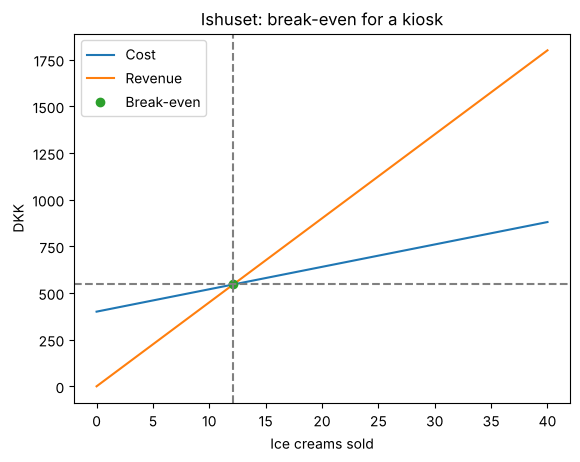

In [38]:
x = np.linspace(0, 40, 100)
cost = fixed + variable * x
revenue = price * x
y_be = price * x_be    # the amount in DKK at break-even

plt.plot(x, cost, label="Cost")
plt.plot(x, revenue, label="Revenue")
plt.plot(x_be, y_be, "o", label="Break-even")
plt.axvline(x_be, linestyle="--", color="grey")
plt.axhline(y_be, linestyle="--", color="grey")
plt.xlabel("Ice creams sold")
plt.ylabel("DKK")
plt.title("Ishuset: break-even for a kiosk")
plt.legend()
plt.show()

In [39]:
#@title Expected output (click to show)
print("Two lines that cross at about 12 ice creams sold and about 545 DKK.")
print("A dot where they cross, a vertical dashed line at about 12 ice creams and a horizontal dashed line at about 545 DKK.")

Two lines that cross at about 12 ice creams sold and about 545 DKK.
A dot where they cross, a vertical dashed line at about 12 ice creams and a horizontal dashed line at about 545 DKK.


### Task 3.3: What if?

1. Set `price` to 50 in the setup cell at the top of the block. Run the setup cell and the cells in tasks 3.1 and 3.2 again. What happens to break-even?
2. Set `price` back to 45 and `fixed` to 600, and repeat.

Set the numbers back to 400, 12 and 45 when you are done.

**Answer in words:** For each change, explain how break-even moves. Use the figure to justify it: what happens to each of the two lines?

**Suggested solution:** At a price of 50 DKK, break-even falls to about 10.5 ice creams (400/38). The revenue line gets steeper, while the cost line is unchanged, so the lines meet earlier. With fixed costs of 600 DKK, break-even rises to about 18.2 ice creams (600/33). The cost line moves up, because it crosses the y-axis higher, while the slope is the same, so the lines meet later.

### Task 3.4: Growth over time

Ishuset has an annual revenue of 1,500,000 DKK and expects growth of 4 percent per year. With continuous growth, the revenue after $t$ years is

$$R(t) = 1{,}500{,}000 \cdot e^{0.04t}$$

In numpy, $e^{(\dots)}$ is written `np.exp(...)`, and the natural logarithm $\ln$ is written `np.log(...)`.

Revenue has doubled when $e^{0.04t} = 2$. Take the logarithm of both sides, and you get $t = \ln(2) / 0.04$. Calculate the doubling time and store it in `t_double`.

In [40]:
R0 = 1500000    # revenue today in DKK
r = 0.04        # growth rate

t_double = np.log(2) / r
print(f"Revenue has doubled after {t_double:.1f} years")

Revenue has doubled after 17.3 years


In [41]:
#@title Check your answer (run the cell)
print("Correct" if np.isclose(R0 * np.exp(r * t_double), 2 * R0) else "Not yet: use np.log(2) and the growth rate r")

Correct


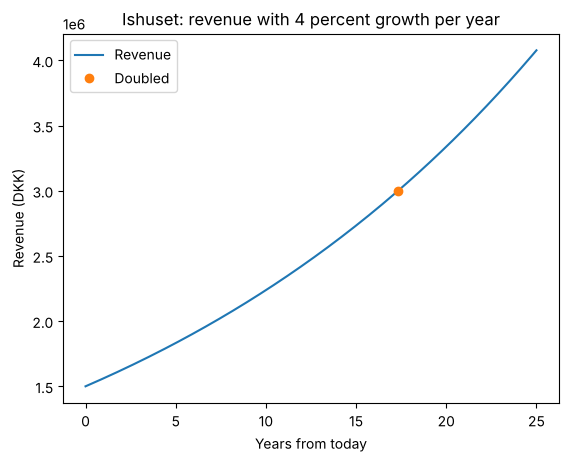

In [42]:
# Plot the revenue R(t) for t from 0 to 25 years.
# Mark the doubling point with a dot, and give the figure axis labels, a title and a legend.
t = np.linspace(0, 25, 200)
R = R0 * np.exp(r * t)

plt.plot(t, R, label="Revenue")
plt.plot(t_double, 2 * R0, "o", label="Doubled")
plt.xlabel("Years from today")
plt.ylabel("Revenue (DKK)")
plt.title("Ishuset: revenue with 4 percent growth per year")
plt.legend()
plt.show()

In [43]:
#@title Expected output (click to show)
print("A curve that starts at 1,500,000 DKK and gets steeper and steeper.")
print("A dot at about 17.3 years and 3,000,000 DKK (the axis may be shown as 1e6, that is, in millions).")

A curve that starts at 1,500,000 DKK and gets steeper and steeper.
A dot at about 17.3 years and 3,000,000 DKK (the axis may be shown as 1e6, that is, in millions).


### Task 3.5: Break-even with sympy

Python can also calculate with symbols, as you do in mathematics. The package sympy does this, and we import it with the alias `sp`.

You may also see `from sympy import symbols, solve`. Then you write `symbols(...)` instead of `sp.symbols(...)`. They are the same functions.

In the cell below, $x$ is defined as a symbol, and cost and revenue are written as expressions in $x$. Note that `x` was a numpy array in task 3.2. Now `x` is a symbol, because we have given the name a new value.

In [44]:
import sympy as sp

x = sp.symbols("x")
C = 400 + 12 * x     # cost
R = 45 * x           # revenue
print(C)
print(R)

12*x + 400
45*x


`sp.Eq(C, R)` is the equation $C = R$, and `sp.solve(equation, x)` solves it for $x$. Fill in the blank.

In [45]:
solution = sp.solve(sp.Eq(C, R), x)
print(solution)
print(type(solution))

[400/33]
<class 'list'>


The result is a list with one solution, and sympy gives it as an exact fraction. Take the solution out of the list with an index, and turn it into a decimal number with `float()`.

In [46]:
x_be_sympy = float(solution[0])
print(f"Break-even at {x_be_sympy:.2f} ice creams sold")

Break-even at 12.12 ice creams sold


In [47]:
#@title Check your answer (run the cell)
print("Correct" if np.isclose(x_be_sympy, 400 / 33) else "Not yet: remember both the index [0] and float()")

Correct


### Task 3.6: Optimization with sympy

Ishuset has modeled the kiosk's daily profit $P(x)$ in DKK as a function of the number of ice creams sold $x$, measured in tens ($x = 30$ means 300 ice creams):

$$P(x) = -0.01x^3 + 0.75x^2 + 18x - 500$$

When many ice creams are sold, the costs of extra staff and freezer space increase, so profit falls again. Find the number of ice creams that gives the largest profit.

First the derivatives. `sp.diff(expression, x)` differentiates the expression with respect to $x$.

In [48]:
x = sp.symbols("x")
P = -0.01 * x**3 + 0.75 * x**2 + 18 * x - 500

# First and second derivative
P1 = sp.diff(P, x)
P2 = sp.diff(P1, x)
print(P1)
print(P2)

-0.03*x**2 + 1.5*x + 18
1.5 - 0.06*x


The critical points are where $P'(x) = 0$. If you give `sp.solve` an expression without an equals sign, it solves the equation *expression = 0*.

In [49]:
critical = sp.solve(P1, x)
print(critical)

[-10.0000000000000, 60.0000000000000]


There are two critical points, one negative and one positive. A negative number of ice creams does not make sense. Choose the positive one with an index (look at the output above to see whether it comes first or last), and do the second derivative test.

In [50]:
x_opt = critical[1]
test = P2.subs(x, x_opt)
print(f"P''({x_opt:.0f}) = {test:.2f}")

if test < 0:
    print("Negative: local maximum")
else:
    print("Positive: local minimum")

P''(60) = -2.10
Negative: local maximum


Calculate the largest profit by substituting `x_opt` into `P` with `.subs()`, and turn the result into a decimal number with `float()`.

In [51]:
P_max = float(P.subs(x, x_opt))
print(f"Largest profit: {P_max:.2f} DKK at {x_opt * 10:.0f} ice creams sold")

Largest profit: 1120.00 DKK at 600 ice creams sold


In [52]:
#@title Check your answer (run the cell)
print("Correct" if np.isclose(float(x_opt), 60) and np.isclose(P_max, 1120) else "Not yet: check that you have chosen the positive critical point")

Correct


To plot, you need numerical values. A sympy expression cannot calculate on a whole numpy array at once, so we substitute one x-value at a time with a list comprehension. `dtype=float` turns the results into ordinary decimal numbers. We use the name `x_vals` for the numerical values, so we do not overwrite the symbol `x`.

In [53]:
x_vals = np.linspace(0, 80, 200)
P_vals = np.array([P.subs(x, v) for v in x_vals], dtype=float)

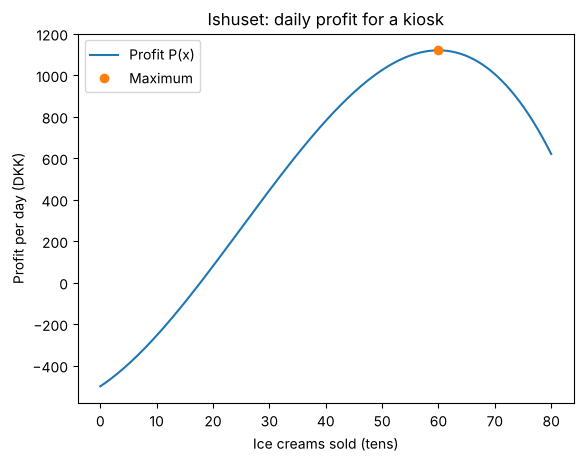

In [54]:
# Plot P_vals against x_vals, and mark the maximum with a dot.
# Give the figure axis labels, a title and a legend.
plt.plot(x_vals, P_vals, label="Profit P(x)")
plt.plot(float(x_opt), P_max, "o", label="Maximum")
plt.xlabel("Ice creams sold (tens)")
plt.ylabel("Profit per day (DKK)")
plt.title("Ishuset: daily profit for a kiosk")
plt.legend()
plt.show()

**Answer in words:** What happens to profit to the left and to the right of the maximum, and how does that relate to $P'(x) = 0$ at the point?

**Suggested solution:** To the left of the maximum, profit rises when more ice creams are sold, so the slope $P'(x)$ is positive. To the right, profit falls, so the slope is negative. At the maximum itself, the slope changes sign and is therefore 0. That is why you find the maximum by solving $P'(x) = 0$. The negative second derivative confirms that the slope goes from positive to negative, that is, that the point is a maximum.

---
## Block 4: Matrices and systems of equations (after Part 4)

The block builds on the dot product from Part 4 in notebook 1. You can solve it before you have done Part 4: task 4.1 explains what you need.

Ishuset makes its own waffle ice cream, milkshakes and slushice in the kitchen in Aalborg. The matrix `A` shows how much milk, sugar and working time one of each item uses. The vector `b` shows what the kitchen has available on a day.

In [55]:
# Setup for block 4: run this cell first
import numpy as np
import sympy as sp

# Resource use per item. Columns: waffle ice cream, milkshake, slushice
A = np.array([
    [ 1,  3,  0],    # milk (dl)
    [20, 30, 40],    # sugar (grams)
    [ 2,  3,  1],    # working time (minutes)
])
b = np.array([250, 6700, 430])     # available per day: milk, sugar, working time
prices = np.array([50, 55, 35])    # selling price per item in DKK

### Task 4.1: Resource use with @

A production plan is a vector with the number of each item. `A @ plan` multiplies each row in `A` by the plan and adds up, like SUMPRODUCT in Excel, once for each resource. The result is the use of milk, sugar and working time.

Calculate the use for the plan below, and find how much is left of each resource.

In [56]:
plan = np.array([100, 40, 70])    # waffle ice creams, milkshakes, slushice

usage = A @ plan
remaining = b - usage
print("Usage:", usage)
print("Remaining:", remaining)

Usage: [ 220 6000  390]
Remaining: [ 30 700  40]


In [57]:
#@title Expected output (click to show)
print("Usage: [ 220 6000  390]")
print("Remaining: [ 30 700  40]")

Usage: [ 220 6000  390]
Remaining: [ 30 700  40]


### Task 4.2: Find the plan that uses everything

The manager wants a plan that uses exactly what the kitchen has available. That is the system of equations $A\mathbf{x} = \mathbf{b}$.

1. Calculate the determinant of `A` with `np.linalg.det`.
2. Solve the system in two ways: with `np.linalg.solve(A, b)` and with the inverse matrix, `np.linalg.inv(A) @ b`.
3. Compare the two solutions with `np.allclose`, which is `np.isclose` for whole arrays.

In [58]:
det_A = np.linalg.det(A)
print(f"Determinant: {det_A}")

x_solve = np.linalg.solve(A, b)
x_inv = np.linalg.inv(A) @ b
print(x_solve)
print(x_inv)
print(np.allclose(x_solve, x_inv))

Determinant: 90.0
[100.  50.  80.]
[100.  50.  80.]
True


In [59]:
#@title Check your answer (run the cell)
print("Correct" if np.allclose(A @ x_solve, b) else "Not yet: the solution must satisfy A @ x = b")

Correct


**Answer in words:** Depending on the computer, the determinant may be shown with a small rounding error, for example 89.99999999999997 instead of 90. Why? And what does it tell you about the system that the determinant is not 0?

**Suggested solution:** `np.linalg.det` calculates with decimal numbers, so the result can get a small rounding error, as we saw in task 2.5. The determinant is 90, so it is different from 0. This means that the system has exactly one solution: there is one and only one plan that uses all resources fully, namely 100 waffle ice creams, 50 milkshakes and 80 slushice.

### Task 4.3: Check and revenue

Check that the plan uses exactly `b` by multiplying `A` by the solution. Then calculate the day's revenue for the plan as the dot product of the plan and the prices.

In [60]:
# Check: use at the solution
check = A @ x_solve
print(check)
print(np.allclose(check, b))

# Revenue
revenue = x_solve @ prices
print(f"Revenue: {revenue:,.0f} DKK.")

[ 250. 6700.  430.]
True
Revenue: 10,550 DKK.


In [61]:
#@title Expected output (click to show)
print("[ 250. 6700.  430.]")
print("True")
print("Revenue: 10,550 DKK.")

[ 250. 6700.  430.]
True
Revenue: 10,550 DKK.


### Task 4.4: Higher price on milkshakes

The manager is considering raising the price of milkshakes by 10 percent. Make a new price vector, and calculate the revenue for the same plan.

In [62]:
prices_new = prices * np.array([1, 1.1, 1])
revenue_new = x_solve @ prices_new
print(f"New revenue: {revenue_new:,.0f} DKK.")

New revenue: 10,825 DKK.


In [63]:
#@title Expected output (click to show)
print("New revenue: 10,825 DKK.")

New revenue: 10,825 DKK.


**Answer in words:** Do you need to solve the system of equations again when the price changes? Justify your answer.

**Suggested solution:** No. The plan is determined by the resource use `A` and what is available, `b`. The prices are not part of the system of equations, so the plan is the same. Only the revenue changes, because it is calculated from the plan and the prices.

### Task 4.5: When the system cannot be solved

A colleague has made a new table, but by mistake the third row has become the sum of the first two. Run both cells, and read the error message.

In [64]:
B = np.array([
    [ 1,  3,  0],
    [20, 30, 40],
    [21, 33, 40],    # = row 1 + row 2
])
print(np.linalg.det(B))

0.0


In [65]:
# ⚠️ This cell fails on purpose
np.linalg.solve(B, b)

LinAlgError: Singular matrix

**Answer in words:** What is the determinant, and what does the error message say (bottom line)? Explain the connection.

**Suggested solution:** The determinant is 0 (or a number very close to 0), and the error message `LinAlgError: Singular matrix` says that the matrix is singular, that is, it cannot be inverted. When a row is a combination of other rows, it contains no new information, and the system has either no solutions or infinitely many. That is why `np.linalg.solve` cannot find one specific plan.

### Task 4.6: The same system with sympy

Sympy can solve systems of equations exactly with `sp.linsolve`. It needs the augmented matrix, where `b` is added as the last column, and the symbols for the unknowns. `np.column_stack` adds `b` as an extra column.

In [66]:
x1, x2, x3 = sp.symbols("x1 x2 x3")
augmented = sp.Matrix(np.column_stack([A, b]))
augmented

Matrix([
[ 1,  3,  0,  250],
[20, 30, 40, 6700],
[ 2,  3,  1,  430]])

In [67]:
solution = sp.linsolve(augmented, (x1, x2, x3))
print(solution)

{(100, 50, 80)}


In [68]:
#@title Expected output (click to show)
print("{(100, 50, 80)}")

{(100, 50, 80)}


---
## Block 5: Combined task, the winter kiosk

Here the whole task is written as text, and the code cells only contain comments. Find the patterns you need yourself, in this notebook and in notebook 1. There are no check cells in this block.

Ishuset is considering keeping the kiosk in Aalborg open in winter and selling hot chocolate. Per day, the manager expects fixed costs of 600 DKK, variable costs of 8 DKK per cup and a selling price of 35 DKK per cup.

**Part 1: Break-even**

1. Define $x$ as a symbol and the costs $C(x)$ and the revenue $R(x)$ as expressions.
2. Find break-even with sympy, and turn the result into a decimal number.
3. Plot $C(x)$ and $R(x)$ for 0 to 50 cups, mark break-even, and give the figure axis labels, a title and a legend.

**Part 2: The best price**

A market survey estimates that $q(p) = 200 - 4p$ cups are sold per day at the price $p$. The profit per day is therefore

$$P(p) = (p - 8)(200 - 4p) - 600$$

1. Define $p$ as a symbol and $P$ as an expression.
2. Find the price that gives the largest profit, and confirm with the second derivative test that it is a maximum.
3. Calculate the largest profit and the number of cups sold at that price.
4. Plot $P(p)$ for $p$ from 8 to 50, and mark the maximum.

**Part 3: Discussion**

1. The best price is lower than the 35 DKK the manager had in mind. Explain from your figure why a lower price can give a larger profit.
2. What happens to the best price if the variable costs rise from 8 to 10 DKK per cup? Try it in the code, and explain.

In [69]:
# Import the packages you need
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

In [70]:
# Part 1.1: Define the symbol x and the expressions C and R
x = sp.symbols("x")
C = 600 + 8 * x
R = 35 * x

In [71]:
# Part 1.2: Find break-even with sympy
be = sp.solve(sp.Eq(C, R), x)
x_be = float(be[0])
print(f"Break-even at {x_be:.2f} cups")

Break-even at 22.22 cups


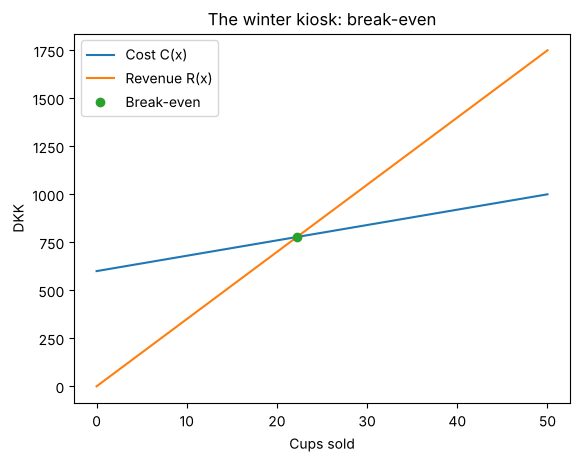

In [72]:
# Part 1.3: Plot C(x) and R(x), and mark break-even
x_vals = np.linspace(0, 50, 100)
C_vals = np.array([C.subs(x, v) for v in x_vals], dtype=float)
R_vals = np.array([R.subs(x, v) for v in x_vals], dtype=float)

plt.plot(x_vals, C_vals, label="Cost C(x)")
plt.plot(x_vals, R_vals, label="Revenue R(x)")
plt.plot(x_be, 35 * x_be, "o", label="Break-even")
plt.xlabel("Cups sold")
plt.ylabel("DKK")
plt.title("The winter kiosk: break-even")
plt.legend()
plt.show()

In [73]:
# Part 2.1: Define p as a symbol and the profit function P
p = sp.symbols("p")
P = (p - 8) * (200 - 4 * p) - 600
print(sp.expand(P))

-4*p**2 + 232*p - 2200


In [74]:
# Part 2.2: Find the best price, and do the second derivative test
P1 = sp.diff(P, p)
P2 = sp.diff(P1, p)
critical = sp.solve(P1, p)
print(critical)

p_opt = critical[0]
print(f"P''({p_opt}) = {P2.subs(p, p_opt)}")   # negative, so a maximum

[29]
P''(29) = -8


In [75]:
# Part 2.3: Largest profit and number of cups sold at the best price
P_max = float(P.subs(p, p_opt))
cups = 200 - 4 * p_opt
print(f"Best price: {float(p_opt):.2f} DKK")
print(f"Largest profit: {P_max:.2f} DKK per day")
print(f"Cups sold: {cups}")

Best price: 29.00 DKK
Largest profit: 1164.00 DKK per day
Cups sold: 84


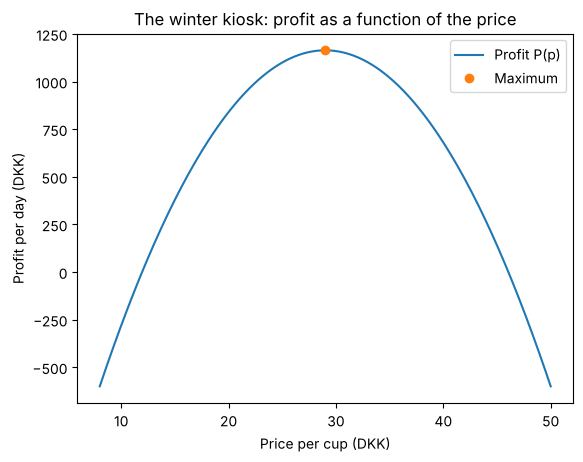

In [76]:
# Part 2.4: Plot P(p), and mark the maximum
p_vals = np.linspace(8, 50, 200)
P_vals = np.array([P.subs(p, v) for v in p_vals], dtype=float)

plt.plot(p_vals, P_vals, label="Profit P(p)")
plt.plot(float(p_opt), P_max, "o", label="Maximum")
plt.xlabel("Price per cup (DKK)")
plt.ylabel("Profit per day (DKK)")
plt.title("The winter kiosk: profit as a function of the price")
plt.legend()
plt.show()

In [77]:
# Part 3.2: Repeat the calculation of the best price with variable costs of 10 DKK
P_10 = (p - 10) * (200 - 4 * p) - 600
p_opt_10 = sp.solve(sp.diff(P_10, p), p)[0]
print(f"Best price with variable costs of 10 DKK: {float(p_opt_10):.2f} DKK")

Best price with variable costs of 10 DKK: 30.00 DKK


**Part 3: Answer in words**

**Suggested solution:** 1. At 35 DKK, only 60 cups are sold, and the profit is 1,020 DKK. At 29 DKK, 84 cups are sold, and the profit is 1,164 DKK. The figure shows that profit rises when the price is lowered from 35 DKK toward 29 DKK: the extra cups sold outweigh the lower price per cup. If the price is lowered below 29 DKK, the margin per cup becomes so small that profit falls again.

2. The best price rises from 29 DKK to 30 DKK. So only half of the kiosk's extra cost of 2 DKK per cup is passed on to customers, because a higher price also means fewer cups sold.

---
End of the suggested solution for the extra exercises for notebook 1.